# Phase 1: Environment Setup & Data Pipeline Architecture

## Step 1.1: Importing Essential Libraries and Verifying GPU Availability
Before we touch any data, we need to bring in our specialized tools (libraries) and ensure PyTorch can talk to our Graphics Processing Unit (GPU). Training Deep Learning models on CPUs is painfully slow; GPUs process mathematical operations in parallel, cutting training time from days to minutes.

In [5]:
# 'torch' is the core Deep Learning framework we use to build, train, and run neural networks.
import torch
# 'zipfile' allows us to read files directly from a compressed .zip archive without extracting it first.
import zipfile
# 'pandas' (pd) is our data manipulation engine, perfect for reading and organizing CSV files into tables (DataFrames).
import pandas as pd
# 'pydicom' is a specialized library used to parse and read medical images in the DICOM standard.
import pydicom
# 'io' provides tools for working with streams of data (like reading bytes into memory).
import io
# 'matplotlib.pyplot' (plt) is used for visualizing data, like plotting our MRI images on the screen.
import matplotlib.pyplot as plt

# Check if PyTorch is connected to the NVIDIA GPU
# torch.cuda.is_available() asks PyTorch if it detects a CUDA-enabled NVIDIA GPU.
print(f"GPU Available: {torch.cuda.is_available()}")

# If a GPU is found, we can query its name.
if torch.cuda.is_available():
    # torch.cuda.get_device_name(0) fetches the hardware name of the first GPU (index 0).
    print(f"GPU Name: {torch.cuda.get_device_name(0)}")

GPU Available: True
GPU Name: NVIDIA GeForce RTX 3050 6GB Laptop GPU


## Step 1.2: Reading the Master Patient Record from the Zip File
**Why stream directly from a zip file?** 
Medical datasets like this one are absolutely massive (often hundreds of gigabytes). If we extract the zip, it doubles the storage space required on our hard drive and creates millions of tiny files, which brutally slows down the operating system's file indexing. By reading directly *from* the zip file in real-time (streaming), we save disk space and drastically improve read speeds. Here, we extract just the CSV containing patient labels.

In [6]:
# Update this path if your zip file is located somewhere else!
zip_path = r"D:\RSNA\rsna-knee-abnormality-detection.zip" 

print("Opening zip file...")
# 'with' context manager ensures the zip file is safely opened and automatically closed when we're done.
# zipfile.ZipFile(path, 'r') opens the archive in read-only mode ('r').
with zipfile.ZipFile(zip_path, 'r') as z:
    
    # Let's read train.csv directly from the zip into a Pandas table
    # z.open('train.csv') creates a byte-stream for the specific CSV file inside the zip.
    with z.open('train.csv') as f:
        # pd.read_csv() takes the byte-stream and converts it into a structured Pandas DataFrame.
        train_df = pd.read_csv(f)
        print("Successfully loaded train.csv!")
        
        # 'display' makes tables look super clean in Jupyter
        # .head() defaults to showing the first 5 rows of our new table.
        display(train_df.head())

Opening zip file...
Successfully loaded train.csv!


,StudyInstanceUID,Report,ACL,MCL,Medial Meniscus,Lateral Meniscus,Medial OA,Lateral OA,PF OA,Effusion,Synovitis,Baker's,Contusion,Fracture
0,1.2.826.0.1.3680043.8.498.10004873229099053869...,Técnica: RMN de la rodilla. Resultados: Rotura...,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN
1,1.2.826.0.1.3680043.8.498.10004945927472656027...,[DATE]: * MR Knie Rechts 15ch AA Klinische Inl...,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN
2,1.2.826.0.1.3680043.8.498.10009278692606631573...,Hallazgos:\nNo hay alteraciones en significati...,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN
3,1.2.826.0.1.3680043.8.498.10009639203170750274...,"In the medial compartment, the meniscus is no...",NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN
4,1.2.826.0.1.3680043.8.498.10013663742400736029...,CONSTATATIONS :\n\nFractures :\nAucune.\n\nAli...,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN


## Step 1.3: Locating and Visualizing Our First DICOM Image
To ensure our pipeline can actually read the complex `.dcm` files, we search the zip archive, pull out the very first MRI slice we can find, decode its raw bytes using `pydicom`, and visualize it using `matplotlib`.

Searching for an MRI image...
Opening image: test_series/1.2.826.0.1.3680043.8.498.10047035057544427318018579121635276191/1.2.826.0.1.3680043.8.498.11580656442259111255675562605155903947/1.2.826.0.1.3680043.8.498.10492923471392639089206565125595901837.dcm


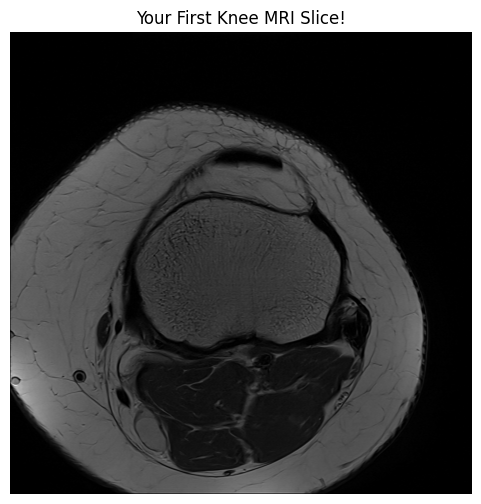

In [7]:
print("Searching for an MRI image...")
# Open the main zip archive again in read mode
with zipfile.ZipFile(zip_path, 'r') as z:
    
    # Find all files ending in .dcm
    # z.namelist() returns a list of EVERY single file path contained inside the zip archive.
    all_files = z.namelist()
    # List comprehension: filters the massive list down to only files that end with the '.dcm' extension.
    dcm_files = [f for f in all_files if f.endswith('.dcm')]
    
    if dcm_files:
        # Grab the path of the very first DICOM file found
        first_image_path = dcm_files[0]
        print(f"Opening image: {first_image_path}")
        
        # Extract just this ONE image into RAM
        # z.open() accesses the specific file inside the zip.
        with z.open(first_image_path) as f:
            # f.read() pulls the raw bytes. io.BytesIO wraps these bytes so pydicom can treat it like a file on disk.
            # pydicom.dcmread() decodes the complex medical metadata and pixel data.
            dicom_data = pydicom.dcmread(io.BytesIO(f.read()))
            # .pixel_array extracts just the raw image matrix (a 2D Numpy array of numbers).
            image_array = dicom_data.pixel_array
            
            # Draw the image
            # Create a 6x6 inch blank canvas for our plot.
            plt.figure(figsize=(6, 6))
            # plt.imshow() paints the array onto the canvas. cmap='gray' tells it to use grayscale mapping.
            plt.imshow(image_array, cmap='gray')
            plt.title("Your First Knee MRI Slice!")
            # Turn off the X and Y axes ticks for a cleaner picture.
            plt.axis('off')
            # Display the plot to the screen.
            plt.show()
    else:
        print("Could not find any .dcm files in the zip. Let's check the folder structure.")

# Phase 2: Building the PyTorch Data Pipeline Engine

## Step 2.1: The Custom Dataset Class (Blueprint)
Deep Learning models need data fed to them in a very specific, structured way. PyTorch uses a `Dataset` class to act as the "engine" that fetches, processes, and packages single data samples. 

**The Dataset Engine Breakdown:**
- `__init__`: The constructor. It sets up our blueprint, taking in the Pandas dataframe, the zip path, and defining which columns hold the diseases.
- `__len__`: The counter. It tells PyTorch exactly how many patient records exist so it knows when a training "epoch" (full pass over the data) is complete.
- `__getitem__`: The workhorse. Given an index number (like patient #5), it reaches into the dataframe, extracts the `StudyInstanceUID`, and packages the target labels into a dictionary. Right now, this is a simplified version; we will upgrade it heavily soon.

In [8]:
# Import the base Dataset class from PyTorch, which we will inherit from.
from torch.utils.data import Dataset
# 'numpy' (np) is heavily used for fast mathematical operations on multi-dimensional arrays.
import numpy as np

# Define our custom class inheriting from PyTorch's Dataset
class RSNAZipDataset(Dataset):
    # __init__ sets up the initial state of the object when we create it.
    def __init__(self, dataframe, zip_path, transform=None):
        # Store the Pandas DataFrame containing our patient records.
        self.dataframe = dataframe
        # Store the path to the zip file.
        self.zip_path = zip_path
        # Store any image transformations we might want to apply later.
        self.transform = transform
        # Initialize a placeholder for the zip file connection (lazy loading).
        self.zip_handler = None
        
        # We explicitly list out the target columns we found
        self.disease_columns = [
            'ACL', 'MCL', 'Medial Meniscus', 'Lateral Meniscus', 
            'Medial OA', 'Lateral OA', 'PF OA', 'Effusion', 
            'Synovitis', "Baker's", 'Contusion', 'Fracture'
        ]

    # __len__ is a special method PyTorch calls to find out how big the dataset is.
    def __len__(self):
        # Return the total number of rows in our DataFrame.
        return len(self.dataframe)

    # __getitem__ is called by PyTorch to grab a specific data sample by its index (idx).
    def __getitem__(self, idx):
        # 1. Open the zip file if it isn't open yet
        if self.zip_handler is None:
            # We open the zip here instead of in __init__ because PyTorch uses multiple 'workers' 
            # (parallel processors) to load data, and they can't easily share an open zip file.
            self.zip_handler = zipfile.ZipFile(self.zip_path, 'r')
            
        # 2. Get the specific row from our table
        # .iloc[idx] gets the row at the integer index 'idx'.
        row = self.dataframe.iloc[idx]
        
        # 3. Get the correct ID!
        study_id = row['StudyInstanceUID']
        
        # 4. Grab the labels 
        # (Note: In the screenshot, some are NaN (Not a Number). 
        # We will write code to handle missing data in Phase 2!)
        # .values extracts the raw numbers, and .astype converts them to 32-bit floats (PyTorch standard).
        labels = row[self.disease_columns].values.astype(np.float32)
        
        # Return a dictionary containing the ID and the raw labels.
        return {"study_id": study_id, "labels": labels}

print("RSNAZipDataset blueprint successfully updated and created!")

RSNAZipDataset blueprint successfully updated and created!


## Step 2.2: Inspecting the Data and Column Names
Before we address the NaN (Not a Number) issue, let's take a quick look at the raw DataFrame and print out the exact column names to confirm our target disease labels are correctly spelled.

In [9]:
# Let's just display the first 3 rows of the ENTIRE table to see the raw data
print("First 3 rows of the dataset:")
# .head(3) limits the display to the first three patient records.
display(train_df.head(3))

# Let's also print the exact column names as a clean Python list
print("\nExact column names in our dataset:")
# .columns fetches the column headers, and list() converts them into a standard Python list.
print(list(train_df.columns))

First 3 rows of the dataset:


,StudyInstanceUID,Report,ACL,MCL,Medial Meniscus,Lateral Meniscus,Medial OA,Lateral OA,PF OA,Effusion,Synovitis,Baker's,Contusion,Fracture
0,1.2.826.0.1.3680043.8.498.10004873229099053869...,Técnica: RMN de la rodilla. Resultados: Rotura...,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN
1,1.2.826.0.1.3680043.8.498.10004945927472656027...,[DATE]: * MR Knie Rechts 15ch AA Klinische Inl...,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN
2,1.2.826.0.1.3680043.8.498.10009278692606631573...,Hallazgos:\nNo hay alteraciones en significati...,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN



Exact column names in our dataset:
['StudyInstanceUID', 'Report', 'ACL', 'MCL', 'Medial Meniscus', 'Lateral Meniscus', 'Medial OA', 'Lateral OA', 'PF OA', 'Effusion', 'Synovitis', "Baker's", 'Contusion', 'Fracture']


## Step 2.3: Ensuring Mathematical Stability (Handling Missing Data)
**Why must we replace NaN values with `0.0`?**
In Deep Learning, Neural Networks learn by multiplying weights and adding biases to the input data, constantly adjusting these numbers using Calculus (Backpropagation). `NaN` means "Not a Number" (usually missing data). If a neural network encounters a `NaN` during multiplication, that mathematical operation results in a `NaN`. This `NaN` cascades through the entire network, corrupting every single weight it touches, rendering the model permanently broken and outputting `NaN` for all future predictions. 

By replacing missing values with `0.0`, we provide a mathematically stable, neutral value that allows the calculus engines to continue functioning normally.

In [10]:
# Define our disease columns explicitly again just to be safe
disease_columns = [
    'ACL', 'MCL', 'Medial Meniscus', 'Lateral Meniscus', 
    'Medial OA', 'Lateral OA', 'PF OA', 'Effusion', 
    'Synovitis', "Baker's", 'Contusion', 'Fracture'
]

# Replace all NaN values with 0
# train_df[disease_columns] selects only the columns we specified.
# .fillna(0) scans those columns and replaces every single 'NaN' value with a literal 0.
train_df[disease_columns] = train_df[disease_columns].fillna(0)

print("Missing values successfully handled!")
# Display the ID and the newly cleaned disease columns to verify the NaNs are gone.
display(train_df[['StudyInstanceUID'] + disease_columns].head(3))

Missing values successfully handled!


,StudyInstanceUID,ACL,MCL,Medial Meniscus,Lateral Meniscus,Medial OA,Lateral OA,PF OA,Effusion,Synovitis,Baker's,Contusion,Fracture
0,1.2.826.0.1.3680043.8.498.10004873229099053869...,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0
1,1.2.826.0.1.3680043.8.498.10004945927472656027...,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0
2,1.2.826.0.1.3680043.8.498.10009278692606631573...,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0


## Step 2.4: Finding a Patient's Associated DICOM Images
To build a fully functioning Dataset engine, it needs to be able to find the correct images for a specific patient. Here, we test the logic to search the zip archive for any `.dcm` files that contain the `StudyInstanceUID` of our first patient.

In [11]:
print("Mapping the folder structure...")

# We use the 'z' zipfile object we opened in the last cell
# We open the zip file again just to ensure it's accessible in this specific block.
with zipfile.ZipFile(zip_path, 'r') as z:
    # Get the master list of all files inside the archive.
    all_files = z.namelist()
    
# Grab the ID of the very first patient in our table
# .iloc[0] grabs the first row, and ['StudyInstanceUID'] pulls that specific string.
first_patient_id = train_df.iloc[0]['StudyInstanceUID']
print(f"Looking for images for patient: {first_patient_id}")

# Search the zip file for any DICOMs belonging to this patient
# List comprehension: searches the master file list for paths containing the patient's ID AND ending in '.dcm'.
patient_files = [f for f in all_files if first_patient_id in f and f.endswith('.dcm')]

# Check if we found any matching files.
if patient_files:
    # len() counts how many images belong to this patient.
    print(f"\nSuccess! Found {len(patient_files)} images for this patient.")
    print(f"The exact path to the first image looks like this:")
    # Print the very first path found in the filtered list.
    print(patient_files[0])
else:
    print("\nUh oh, could not find images for this patient.")

Mapping the folder structure...
Looking for images for patient: 1.2.826.0.1.3680043.8.498.10004873229099053869093324292195817260

Success! Found 94 images for this patient.
The exact path to the first image looks like this:
train_series/1.2.826.0.1.3680043.8.498.10004873229099053869093324292195817260/1.2.826.0.1.3680043.8.498.12343110195036213483454091715412333772/1.2.826.0.1.3680043.8.498.10374285052733466977592225981851620435.dcm


# Phase 3: Advanced Image Processing & PyTorch Integration

## Step 3.1: Normalization and Resizing
**Why do we use OpenCV (`cv2`) to shrink the DICOM images to 224x224?**
Raw MRI images are extremely high resolution (e.g., 1024x1024 or larger). A modern GPU has a strict physical limit on Video RAM (VRAM), usually between 8GB and 24GB. 
1. If we feed full-resolution images into a deep neural network, the complex multi-dimensional matrices will instantly exceed the GPU's VRAM, causing an Out-Of-Memory (OOM) crash.
2. Shrinking images to `224x224` is an industry standard (used by massive pre-trained models like ResNet) that preserves enough structural detail for the AI to learn, while keeping memory usage low enough to process "batches" of multiple images simultaneously.

Extracting and resizing: 1.2.826.0.1.3680043.8.498.10374285052733466977592225981851620435.dcm


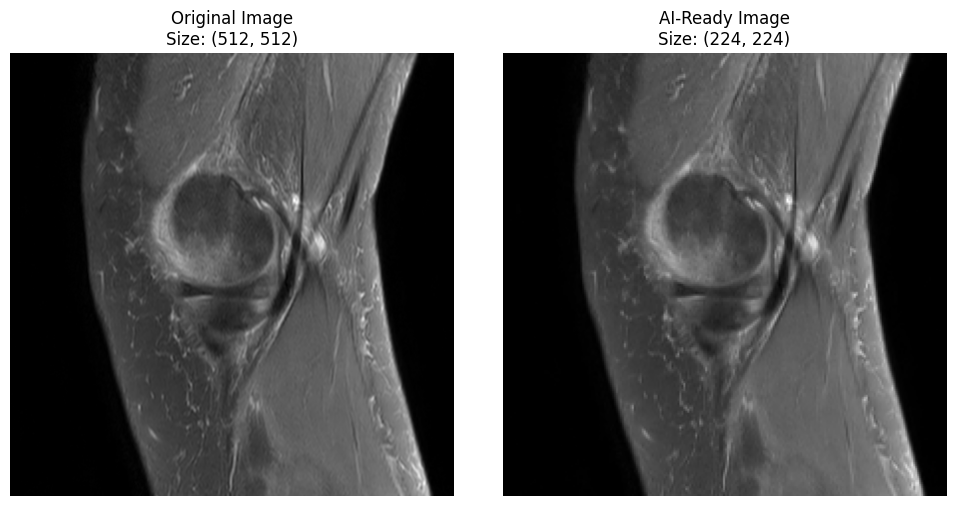

In [12]:
import pydicom
import io
# 'cv2' is OpenCV, an incredibly fast C++ based library used for computer vision and image manipulation.
import cv2
import numpy as np
import matplotlib.pyplot as plt

def process_and_resize_image(dicom_bytes, target_size=224):
    # 1. Read the raw DICOM from memory
    # Wrap the raw bytes in io.BytesIO so pydicom can parse it.
    dicom_data = pydicom.dcmread(io.BytesIO(dicom_bytes))
    # Extract the pixel array and convert it to a floating-point matrix for high-precision math.
    image = dicom_data.pixel_array.astype(float)
    
    # 2. Normalize the pixels to be between 0 and 1 (AI loves numbers between 0 and 1)
    # This also fixes contrast issues!
    image_min = image.min()
    image_max = image.max()
    # Avoid dividing by zero if the image is completely black.
    if image_max > image_min:
        # Min-Max Normalization: forces all pixel brightness values into a tight 0.0 to 1.0 range.
        image = (image - image_min) / (image_max - image_min)
    else:
        # If the image is completely blank, just return an array of zeros.
        image = np.zeros(image.shape)
        
    # 3. Resize the image to 224x224
    # cv2.resize takes the numpy matrix and perfectly scales it down to our target size.
    image_resized = cv2.resize(image, (target_size, target_size))
    
    # Return both versions so we can compare them visually.
    return image, image_resized

# Let's use the exact path we just found in the last cell
exact_image_path = patient_files[0] 
# .split('/')[-1] grabs just the filename at the end of the path string.
print(f"Extracting and resizing: {exact_image_path.split('/')[-1]}")

with zipfile.ZipFile(zip_path, 'r') as z:
    with z.open(exact_image_path) as f:
        # Read the raw bytes from the zip
        raw_bytes = f.read()
        
        # Pass it to our new function!
        original_img, resized_img = process_and_resize_image(raw_bytes)
        
        # Let's plot them side-by-side
        # Create a figure with 1 row and 2 columns of plots.
        fig, axes = plt.subplots(1, 2, figsize=(10, 5))
        
        # Plot original on the left (index 0)
        axes[0].imshow(original_img, cmap='gray')
        axes[0].set_title(f"Original Image\nSize: {original_img.shape}")
        axes[0].axis('off')
        
        # Plot resized on the right (index 1)
        axes[1].imshow(resized_img, cmap='gray')
        axes[1].set_title(f"AI-Ready Image\nSize: {resized_img.shape}")
        axes[1].axis('off')
        
        # Adjust spacing automatically.
        plt.tight_layout()
        plt.show()

## Step 3.2: The Final, Upgraded Dataset Engine
Here, we combine all of our knowledge into the final `RSNAZipDataset` class.

**Why does PyTorch require final tensor shapes to be `(Channels, Height, Width)`?**
When we load an image in Python via OpenCV, its shape is mathematically interpreted as `(Height, Width, Channels)` or `(H, W, C)`. For example, a `224x224` image with 3 color channels (RGB) is `(224, 224, 3)`. 
However, PyTorch's underlying C++ and CUDA code is aggressively optimized for convolutional operations that expect the *Channels* to be the very first dimension: `(C, H, W)`. Even though MRIs are grayscale (1 channel), PyTorch still strictly enforces this `(1, 224, 224)` 3D structure. We achieve this by artificially adding a dimension using `.unsqueeze(0)`.

In [13]:
import torch
from torch.utils.data import Dataset
import pydicom
import io
import cv2
import numpy as np
import zipfile

# Final Upgraded Dataset Class
class RSNAZipDataset(Dataset):
    def __init__(self, dataframe, zip_path, target_size=224):
        # Store initial inputs
        self.dataframe = dataframe
        self.zip_path = zip_path
        self.target_size = target_size
        self.zip_handler = None
        
        # The exact target columns we cleaned earlier
        self.disease_columns = [
            'ACL', 'MCL', 'Medial Meniscus', 'Lateral Meniscus', 
            'Medial OA', 'Lateral OA', 'PF OA', 'Effusion', 
            'Synovitis', "Baker's", 'Contusion', 'Fracture'
        ]
        
        # We create a list of all files in the zip ONE time when this initializes
        # so we don't have to search the massive zip file over and over.
        print("Indexing zip file for fast access... (this takes a few seconds)")
        with zipfile.ZipFile(self.zip_path, 'r') as z:
            self.all_files = z.namelist()

    def __len__(self):
        # Tells PyTorch how many patients we have
        return len(self.dataframe)

    def __getitem__(self, idx):
        # 1. Open the zip file if it isn't open yet (lazy loading)
        if self.zip_handler is None:
            self.zip_handler = zipfile.ZipFile(self.zip_path, 'r')
            
        # 2. Get the specific patient row and ID
        row = self.dataframe.iloc[idx]
        study_id = row['StudyInstanceUID']
        
        # 3. Find the FIRST image for this patient
        # (For this baseline, we will just train the AI on one slice per patient)
        patient_image_path = None
        # Loop through our pre-indexed master list of files.
        for f in self.all_files:
            # If the file path contains the patient's ID and is a DICOM file...
            if study_id in f and f.endswith('.dcm'):
                patient_image_path = f
                break # Stop searching as soon as we find the first one!
                
        # 4. Extract, Normalize, and Resize the image using OpenCV
        if patient_image_path:
            # Read directly from the zip stream
            with self.zip_handler.open(patient_image_path) as f:
                # Decode bytes to DICOM
                dicom_data = pydicom.dcmread(io.BytesIO(f.read()))
                # Convert to floating point matrix
                image = dicom_data.pixel_array.astype(float)
                
                # Min-Max Normalization (0.0 to 1.0)
                image_min = image.min()
                image_max = image.max()
                if image_max > image_min:
                    image = (image - image_min) / (image_max - image_min)
                else:
                    image = np.zeros(image.shape)
                    
                # Resize matrix to our strict 224x224 memory constraint
                image_resized = cv2.resize(image, (self.target_size, self.target_size))
        else:
            # Fallback if a patient has no images (creates a blank black square)
            image_resized = np.zeros((self.target_size, self.target_size))
            
        # 5. Format for PyTorch: AI needs (Channels, Height, Width)
        # Even though it is grayscale, PyTorch expects 1 color channel: (1, 224, 224)
        # torch.tensor() converts our numpy matrix into a PyTorch Tensor.
        # .unsqueeze(0) forcefully adds a new dimension at index 0 (the Channels position).
        image_tensor = torch.tensor(image_resized, dtype=torch.float32).unsqueeze(0)
        
        # 6. Grab the labels and convert them to a PyTorch Tensor
        # PyTorch requires targets to be in Tensor format as well.
        labels = torch.tensor(row[self.disease_columns].values.astype(np.float32))
        
        # Return the final dictionary package!
        return {"image": image_tensor, "labels": labels}

print("\nFinal Dataset Engine Successfully Compiled!")


Final Dataset Engine Successfully Compiled!


## Step 3.3: Engine Verification
Let's fire up our engine, ask it for the very first patient's data, and verify the structural shapes. If our tensor shapes aren't perfect, PyTorch will immediately crash when we try to pass this data into a Neural Network later.

In [14]:
# 1. Create the dataset object
# (Make sure zip_path and train_df are still defined from your earlier cells)
# We initialize our blueprint, passing in the cleaned dataframe and the zip location.
my_dataset = RSNAZipDataset(dataframe=train_df, zip_path=zip_path, target_size=224)

# 2. Ask for the very first patient
# By accessing index [0], PyTorch calls our __getitem__ method under the hood!
sample = my_dataset[0]

# 3. Inspect the final AI-ready output
print(f"\n--- Output Analysis ---")
# .shape shows us the structural dimensions of our tensor. We want [1, 224, 224].
print(f"Image Tensor Shape: {sample['image'].shape}")
# We want [12] because we have 12 specific diseases we are predicting.
print(f"Labels Tensor Shape: {sample['labels'].shape}")
# Output the actual binary labels.
print(f"Label Values: {sample['labels']}")

Indexing zip file for fast access... (this takes a few seconds)

--- Output Analysis ---
Image Tensor Shape: torch.Size([1, 224, 224])
Labels Tensor Shape: torch.Size([12])
Label Values: tensor([0., 0., 0., 0., 0., 0., 0., 0., 0., 0., 0., 0.])


In [20]:
import torch
import torch.nn as nn
import torch.optim as optim
from torch.utils.data import DataLoader
import timm
from tqdm import tqdm

# ==========================================
# 1. BUILD THE MODEL (THE BRAIN)
# ==========================================
class RSNAKneeModel(nn.Module):
    def __init__(self, model_name='efficientnet_b0', num_classes=12):
        super().__init__()
        
        # Download the pre-trained backbone (grayscale inputs)
        print(f"Downloading {model_name} backbone...")
        self.backbone = timm.create_model(
            model_name, 
            pretrained=True, 
            in_chans=1, 
            num_classes=0 
        )
        
        # Attach our custom head for the 12 specific knee abnormalities
        self.head = nn.Linear(self.backbone.num_features, num_classes)
        
    def forward(self, x):
        features = self.backbone(x)
        output = self.head(features)
        return output

# Move the model directly to your NVIDIA GPU!
device = torch.device("cuda" if torch.cuda.is_available() else "cpu")
model = RSNAKneeModel().to(device)
print(f"\nModel successfully built and moved to: {device}")

# ==========================================
# 2. SETUP THE DATA ENGINE
# ==========================================
# (Make sure 'my_dataset' is still loaded in your Jupyter memory from earlier!)
train_loader = DataLoader(my_dataset, batch_size=8, shuffle=True)

# ==========================================
# 3. CONFIGURE THE GRADER & OPTIMIZER
# ==========================================
criterion = nn.BCEWithLogitsLoss() 
optimizer = optim.Adam(model.parameters(), lr=0.001)

# ==========================================
# 4. THE LIVE TRAINING LOOP
# ==========================================
epochs = 20 
print("\nStarting the live training engine...")

for epoch in range(epochs):
    model.train() 
    running_loss = 0.0
    
    # Wrap our loader in tqdm to generate the live visual slider
    progress_bar = tqdm(train_loader, desc=f"Epoch {epoch+1}/{epochs}")
    
    for batch in progress_bar:
        # Move the batch of images and answers directly into the GPU
        images = batch['image'].to(device)
        labels = batch['labels'].to(device)
        
        # Step A: Clear out the math from the previous image
        optimizer.zero_grad()
        
        # Step B: The model makes its guess
        predictions = model(images)
        
        # Step C: The Grader calculates how wrong the guess was
        loss = criterion(predictions, labels)
        
        # Step D: Backpropagation! (The model actually learns here)
        loss.backward()
        optimizer.step()
        
        # Update the live slider with the current Loss score
        running_loss += loss.item()
        progress_bar.set_postfix({'Loss': f"{loss.item():.4f}"})
        
    # Calculate the average score for the whole epoch
    epoch_loss = running_loss / len(train_loader)
    print(f"Epoch {epoch+1} Completed! Average Loss: {epoch_loss:.4f}\n")


Model successfully built and moved to: cuda

Starting the live training engine...


Epoch 1/20: 100%|██████████| 551/551 [05:07<00:00,  1.79it/s, Loss=0.0028]


Epoch 1 Completed! Average Loss: 0.0429



Epoch 2/20: 100%|██████████| 551/551 [05:05<00:00,  1.80it/s, Loss=0.4917]


Epoch 2 Completed! Average Loss: 0.0322



...

Epoch 3 Completed! Average Loss: 0.0308



Epoch 4/20: 100%|██████████| 551/551 [05:07<00:00,  1.79it/s, Loss=0.0125]


Epoch 4 Completed! Average Loss: 0.0301



Epoch 5/20:  27%|██▋       | 149/551 [01:22<03:41,  1.81it/s, Loss=0.0012]


KeyboardInterrupt: 

In [16]:
import os

# Define a save path in your project folder
save_path = 'rsna_knee_model_v1.pth'

# Extract the learned weights from the model and save them to a file
torch.save(model.state_dict(), save_path)

print(f"Success! The AI's brain has been permanently saved to: {os.path.abspath(save_path)}")


NameError: name 'model' is not defined

In [17]:
import torch
import torch.nn as nn
import timm

# 1. Remind Python what the blueprint (architecture) looks like
class RSNAKneeModel(nn.Module):
    def __init__(self, model_name='efficientnet_b0', num_classes=12):
        super().__init__()
        self.backbone = timm.create_model(
            model_name, 
            pretrained=False, # Set to False because we are loading our own saved weights!
            in_chans=1, 
            num_classes=0 
        )
        self.head = nn.Linear(self.backbone.num_features, num_classes)
        
    def forward(self, x):
        features = self.backbone(x)
        output = self.head(features)
        return output

# 2. Create the blank model and move it to the GPU
device = torch.device("cuda" if torch.cuda.is_available() else "cpu")
model = RSNAKneeModel().to(device)

# 3. Load your heavily trained weights into the blank model
save_path = 'rsna_knee_model_v1.pth'
model.load_state_dict(torch.load(save_path, weights_only=True))

print("Brain successfully loaded from disk!")

Brain successfully loaded from disk!


Running the MRI through the neural network...

--- AI Diagnosis for Patient #5 ---
ACL               :  0.24% chance 
MCL               :  0.04% chance 
Medial Meniscus   :  0.64% chance 
Lateral Meniscus  :  0.23% chance 
Medial OA         :  0.13% chance 
Lateral OA        :  0.25% chance 
PF OA             :  0.49% chance 
Effusion          :  0.67% chance 
Synovitis         :  0.51% chance 
Baker's           :  0.17% chance 
Contusion         :  0.01% chance 
Fracture          :  1.31% chance 


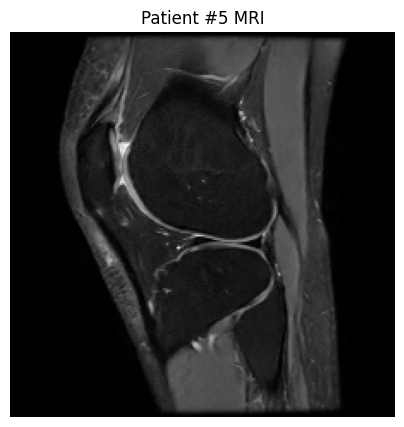

In [18]:
import torch
import matplotlib.pyplot as plt

# 1. Put the AI in 'Test Mode'
# This locks the dropout and normalization layers for consistent testing
model.eval()

# 2. Grab a random patient from our engine (let's pick patient #5)
sample_idx = 5
sample = my_dataset[sample_idx]

image_tensor = sample['image']
true_labels = sample['labels']

# 3. Prepare the image for the GPU 
# PyTorch expects a "batch" of images, even if it is just one. 
# .unsqueeze(0) turns [1, 224, 224] into [1, 1, 224, 224]
gpu_image = image_tensor.unsqueeze(0).to(device)

print("Running the MRI through the neural network...")

# 4. Make the prediction!
# torch.no_grad() turns off the massive calculus engine to save VRAM
with torch.no_grad():
    raw_output = model(gpu_image)
    
    # The output is raw math logits. We use a 'Sigmoid' function to crush those numbers into 0-100% probabilities!
    probabilities = torch.sigmoid(raw_output)[0]

# 5. Display the medical report
disease_names = my_dataset.disease_columns
print(f"\n--- AI Diagnosis for Patient #{sample_idx} ---")

for i in range(len(disease_names)):
    disease = disease_names[i]
    ai_confidence = probabilities[i].item() * 100
    true_value = true_labels[i].item()
    
    # Add a visual marker if the Kaggle CSV says the patient actually has this disease
    truth_marker = "<-- ACTUAL DIAGNOSIS" if true_value == 1.0 else ""
    
    print(f"{disease: <18}: {ai_confidence:5.2f}% chance {truth_marker}")
    
# 6. Show the knee image we just analyzed
plt.figure(figsize=(5, 5))
plt.imshow(image_tensor[0].numpy(), cmap='gray')
plt.title(f"Patient #{sample_idx} MRI")
plt.axis('off')
plt.show()

Hunting for a patient with a confirmed abnormality...
Found one! Patient #29 has an abnormality.

--- AI Diagnosis for Patient #29 ---
PF OA             :  1.07% chance <-- ACTUAL DIAGNOSIS
Effusion          :  1.34% chance <-- ACTUAL DIAGNOSIS


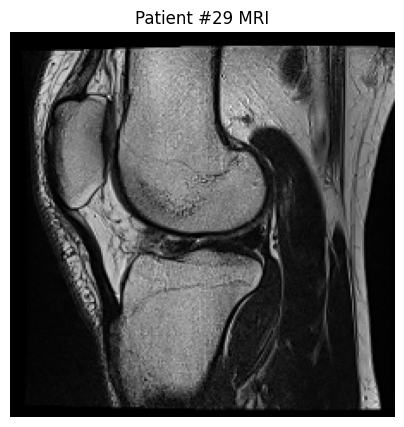

In [19]:
print("Hunting for a patient with a confirmed abnormality...")

# Scan through the dataset to find a sick patient
target_idx = None
for i in range(len(my_dataset)):
    if my_dataset[i]['labels'].sum() > 0: # If they have at least 1 disease
        target_idx = i
        break

if target_idx is not None:
    print(f"Found one! Patient #{target_idx} has an abnormality.\n")
    
    # Run the Inference exactly as before
    sample = my_dataset[target_idx]
    image_tensor = sample['image']
    true_labels = sample['labels']
    gpu_image = image_tensor.unsqueeze(0).to(device)

    with torch.no_grad():
        raw_output = model(gpu_image)
        probabilities = torch.sigmoid(raw_output)[0]

    disease_names = my_dataset.disease_columns
    print(f"--- AI Diagnosis for Patient #{target_idx} ---")
    
    for i in range(len(disease_names)):
        disease = disease_names[i]
        ai_confidence = probabilities[i].item() * 100
        true_value = true_labels[i].item()
        
        truth_marker = "<-- ACTUAL DIAGNOSIS" if true_value == 1.0 else ""
        if true_value == 1.0 or ai_confidence > 10.0: # Only print interesting ones to save space
            print(f"{disease: <18}: {ai_confidence:5.2f}% chance {truth_marker}")
            
    plt.figure(figsize=(5, 5))
    plt.imshow(image_tensor[0].numpy(), cmap='gray')
    plt.title(f"Patient #{target_idx} MRI")
    plt.axis('off')
    plt.show()
else:
    print("Could not find any abnormalities in the current dataset sample.")